# Import

In [1]:
from IPython.display import display
import pandas as pd
import numpy as np
from scipy.stats import zscore
import seaborn as sns
import matplotlib.pyplot as plt
import scipy.stats as stats
from scipy.stats import normaltest
from sklearn.preprocessing import LabelEncoder
from mlxtend.frequent_patterns import apriori, association_rules
from mlxtend.preprocessing import TransactionEncoder
from mlxtend.frequent_patterns import apriori, association_rules

In [2]:
## Import Excel
data = pd.read_csv("inventory_items.csv", encoding="latin-1") # Membaca file csv

df = pd.DataFrame(data) # Mengubahnya menjadi DataFrame

pd.set_option("display.max_columns", None)
df

,id,product_id,created_at,sold_at,cost,product_category,product_name,product_brand,product_retail_price,product_department,product_sku,product_distribution_center_id
0,67971,13844,2022-07-02 07:09:20+00:00,2022-07-24 06:33:20+00:00,2.76804,Accessories,(ONE) 1 Satin Headband,Funny Girl Designs,6.99,Women,2A3E953A5E3D81E67945BCE5519F84C8,7
1,67972,13844,2023-12-20 03:28:00+00:00,NaN,2.76804,Accessories,(ONE) 1 Satin Headband,Funny Girl Designs,6.99,Women,2A3E953A5E3D81E67945BCE5519F84C8,7
2,67973,13844,2023-06-04 02:53:00+00:00,NaN,2.76804,Accessories,(ONE) 1 Satin Headband,Funny Girl Designs,6.99,Women,2A3E953A5E3D81E67945BCE5519F84C8,7
3,72863,13844,2021-10-16 22:58:52+00:00,2021-11-22 02:19:52+00:00,2.76804,Accessories,(ONE) 1 Satin Headband,Funny Girl Designs,6.99,Women,2A3E953A5E3D81E67945BCE5519F84C8,7
4,72864,13844,2021-08-07 16:33:00+00:00,NaN,2.76804,Accessories,(ONE) 1 Satin Headband,Funny Girl Designs,6.99,Women,2A3E953A5E3D81E67945BCE5519F84C8,7
...,...,...,...,...,...,...,...,...,...,...,...,...
490700,311018,25590,2021-12-07 12:47:00+00:00,NaN,10.39200,Underwear,ck one Men's Micro Slim Fit Boxer,Calvin Klein,24.00,Men,F220707C3AFE39D1779E0A34AF72BB7F,3
490701,451084,25590,2023-10-10 11:57:57+00:00,2023-11-27 11:28:57+00:00,10.39200,Underwear,ck one Men's Micro Slim Fit Boxer,Calvin Klein,24.00,Men,F220707C3AFE39D1779E0A34AF72BB7F,3
490702,451085,25590,2020-11-20 05:55:00+00:00,NaN,10.39200,Underwear,ck one Men's Micro Slim Fit Boxer,Calvin Klein,24.00,Men,F220707C3AFE39D1779E0A34AF72BB7F,3
490703,486057,25590,2023-02-26 22:35:12+00:00,2023-04-23 01:24:12+00:00,10.39200,Underwear,ck one Men's Micro Slim Fit Boxer,Calvin Klein,24.00,Men,F220707C3AFE39D1779E0A34AF72BB7F,3


## Data Head - Tail

In [3]:
# Copy data biar tidak ditiban
df_copy = df.copy()
df_copy.head()

,id,product_id,created_at,sold_at,cost,product_category,product_name,product_brand,product_retail_price,product_department,product_sku,product_distribution_center_id
0,67971,13844,2022-07-02 07:09:20+00:00,2022-07-24 06:33:20+00:00,2.76804,Accessories,(ONE) 1 Satin Headband,Funny Girl Designs,6.99,Women,2A3E953A5E3D81E67945BCE5519F84C8,7
1,67972,13844,2023-12-20 03:28:00+00:00,NaN,2.76804,Accessories,(ONE) 1 Satin Headband,Funny Girl Designs,6.99,Women,2A3E953A5E3D81E67945BCE5519F84C8,7
2,67973,13844,2023-06-04 02:53:00+00:00,NaN,2.76804,Accessories,(ONE) 1 Satin Headband,Funny Girl Designs,6.99,Women,2A3E953A5E3D81E67945BCE5519F84C8,7
3,72863,13844,2021-10-16 22:58:52+00:00,2021-11-22 02:19:52+00:00,2.76804,Accessories,(ONE) 1 Satin Headband,Funny Girl Designs,6.99,Women,2A3E953A5E3D81E67945BCE5519F84C8,7
4,72864,13844,2021-08-07 16:33:00+00:00,NaN,2.76804,Accessories,(ONE) 1 Satin Headband,Funny Girl Designs,6.99,Women,2A3E953A5E3D81E67945BCE5519F84C8,7


In [4]:
df_copy.tail()

,id,product_id,created_at,sold_at,cost,product_category,product_name,product_brand,product_retail_price,product_department,product_sku,product_distribution_center_id
490700,311018,25590,2021-12-07 12:47:00+00:00,NaN,10.392,Underwear,ck one Men's Micro Slim Fit Boxer,Calvin Klein,24.0,Men,F220707C3AFE39D1779E0A34AF72BB7F,3
490701,451084,25590,2023-10-10 11:57:57+00:00,2023-11-27 11:28:57+00:00,10.392,Underwear,ck one Men's Micro Slim Fit Boxer,Calvin Klein,24.0,Men,F220707C3AFE39D1779E0A34AF72BB7F,3
490702,451085,25590,2020-11-20 05:55:00+00:00,NaN,10.392,Underwear,ck one Men's Micro Slim Fit Boxer,Calvin Klein,24.0,Men,F220707C3AFE39D1779E0A34AF72BB7F,3
490703,486057,25590,2023-02-26 22:35:12+00:00,2023-04-23 01:24:12+00:00,10.392,Underwear,ck one Men's Micro Slim Fit Boxer,Calvin Klein,24.0,Men,F220707C3AFE39D1779E0A34AF72BB7F,3
490704,486058,25590,2022-09-12 13:52:00+00:00,NaN,10.392,Underwear,ck one Men's Micro Slim Fit Boxer,Calvin Klein,24.0,Men,F220707C3AFE39D1779E0A34AF72BB7F,3


# Data Exploration

## Info

In [5]:
df_copy.info()

<class 'pandas.DataFrame'>
RangeIndex: 490705 entries, 0 to 490704
Data columns (total 12 columns):
 #   Column                          Non-Null Count   Dtype  
---  ------                          --------------   -----  
 0   id                              490705 non-null  int64  
 1   product_id                      490705 non-null  int64  
 2   created_at                      490705 non-null  str    
 3   sold_at                         181759 non-null  str    
 4   cost                            490705 non-null  float64
 5   product_category                490705 non-null  str    
 6   product_name                    490676 non-null  str    
 7   product_brand                   490304 non-null  str    
 8   product_retail_price            490705 non-null  float64
 9   product_department              490705 non-null  str    
 10  product_sku                     490705 non-null  str    
 11  product_distribution_center_id  490705 non-null  int64  
dtypes: float64(2), int64(3), st

### Insight
Berdasarkan hasil pemeriksaan menggunakan `df_copy.info()`, dataset memiliki 490705 baris dan 12 kolom yang merepresentasikan data siswa. Dataset terdiri dari beberapa tipe data, yaitu 7 `str` (teks/kategorikal), 3 `int` (bilangan bulat), dan 2 `float` (bilangan desimal). Pada data inventory_items terdapat kolom yang memiliki tipe data yang salah, yaitu created_at, dan sold_at yang memiliki tipe data string. Maka dari itu perluh mengubah dua kolom tersebut menjadi tipe data datetime.

### Cleaning Tipe Data

In [6]:
df_copy['created_at'] = pd.to_datetime(df_copy['created_at'], format='mixed')
df_copy['sold_at'] = pd.to_datetime(df_copy['sold_at'], format='mixed')

In [7]:
df_copy.info()

<class 'pandas.DataFrame'>
RangeIndex: 490705 entries, 0 to 490704
Data columns (total 12 columns):
 #   Column                          Non-Null Count   Dtype              
---  ------                          --------------   -----              
 0   id                              490705 non-null  int64              
 1   product_id                      490705 non-null  int64              
 2   created_at                      490705 non-null  datetime64[us, UTC]
 3   sold_at                         181759 non-null  datetime64[us, UTC]
 4   cost                            490705 non-null  float64            
 5   product_category                490705 non-null  str                
 6   product_name                    490676 non-null  str                
 7   product_brand                   490304 non-null  str                
 8   product_retail_price            490705 non-null  float64            
 9   product_department              490705 non-null  str                
 10  product

## describe

In [8]:
df_copy.describe()

,id,product_id,cost,product_retail_price,product_distribution_center_id
count,490705.000000,490705.000000,490705.000000,490705.000000,490705.000000
mean,245353.000000,15254.164465,28.658986,59.569440,5.011514
std,141654.476259,8410.586173,31.009435,66.592452,2.900016
min,1.000000,1.000000,0.008300,0.020000,1.000000
25%,122677.000000,7984.000000,11.368000,24.500000,2.000000
50%,245353.000000,15970.000000,19.832000,39.990002,5.000000
75%,368029.000000,22502.000000,34.550301,69.949997,8.000000
max,490705.000000,29120.000000,557.151002,999.000000,10.000000


### Insight
Tujuan penggunaan kode df_copy.describe() adalah untuk memperoleh gambaran statistik deskriptif dari setiap kolom numerik dalam dataset. Informasi yang diperoleh meliputi jumlah data (count), nilai rata-rata (mean), standar deviasi (std), nilai minimum (min), dan nilai maksimum (max).

## Inkonsistensi

In [9]:
# Pilih kolom bertipe objek (teks)
kolom_teks = df_copy.select_dtypes(include=["object", "category", "str", "int", "float"]).columns ## Numerik belum termasuk float, Falidasi seluruh

for col in kolom_teks:
    print(f"=== Kolom: {col} ===")
    print(f"Jumlah nilai unik asli: {df_copy[col].nunique()}")
    # Menampilkan 5 nilai teratas untuk quick check
    print(df[col].value_counts())
    print("\n" + "-"*40 + "\n")

=== Kolom: id ===
Jumlah nilai unik asli: 490705
id
67971     1
67972     1
67973     1
72863     1
72864     1
         ..
311018    1
451084    1
451085    1
486057    1
486058    1
Name: count, Length: 490705, dtype: int64

----------------------------------------

=== Kolom: product_id ===
Jumlah nilai unik asli: 29046
product_id
18795    58
27625    53
21086    52
25209    51
17045    51
         ..
17017     2
16937     2
26170     2
26444     2
25954     2
Name: count, Length: 29046, dtype: int64

----------------------------------------

=== Kolom: cost ===
Jumlah nilai unik asli: 26314
cost
10.750000    182
13.550000    179
11.450000    166
11.975000    147
10.800000    142
            ... 
9.511800       2
76.176000      2
53.550000      2
23.645271      2
9.720000       2
Name: count, Length: 26314, dtype: int64

----------------------------------------

=== Kolom: product_category ===
Jumlah nilai unik asli: 26
product_category
Intimates                        36353
Jeans  

### Insight
Setelah melakukan pemeriksaan typo pada seluruh tipe data dalam dataset `inventory_items`, tidak ditemukan indikasi kesalahan penulisan yang jelas pada kategori maupun perbedaan penggunaan huruf kapital dan spasi. Sementara itu, pada kolom numerik, rentang nilai yang ditemukan secara umum masih masuk akal berdasarkan karakteristik masing-masing variabel. Meskipun demikian, beberapa nilai ekstrem tetap perlu dievaluasi lebih lanjut untuk memastikan bahwa nilai tersebut bukan berasal dari kesalahan penginputan data. Dengan demikian, berdasarkan pemeriksaan awal, belum ditemukan indikasi typo yang signifikan pada dataset dan data dapat dilanjutkan ke tahap eksplorasi berikutnya dengan tetap memperhatikan validitas nilai.

## Missing Value

In [10]:
Missing_count = df_copy.isnull().sum()
Missing_percent = (df_copy.isnull().sum() / len(df_copy)) * 100

# Menggabungkan jumlah dan persentase ke dalam satu DataFrame agar rapi
missing_summary = pd.DataFrame({
    'Jumlah Missing': Missing_count,
    'Persentase (%)': Missing_percent
})

# Mengurutkan dari jumlah missing value terbanyak (opsional)
missing_summary = missing_summary.sort_values(by='Jumlah Missing', ascending=False)

# Memformat angka persentase agar rapi (misal 2 angka di belakang koma)
missing_summary['Persentase (%)'] = missing_summary['Persentase (%)'].round(2)

print("Ringkasan Missing Value:")
print(missing_summary)

Ringkasan Missing Value:
                                Jumlah Missing  Persentase (%)
sold_at                                 308946           62.96
product_brand                              401            0.08
product_name                                29            0.01
id                                           0            0.00
created_at                                   0            0.00
product_id                                   0            0.00
product_category                             0            0.00
cost                                         0            0.00
product_retail_price                         0            0.00
product_department                           0            0.00
product_sku                                  0            0.00
product_distribution_center_id               0            0.00


Terdapat missing value pada kolom: *sold_at, time_management_score, product_brand, dan product_name* yang perlu diperiksa penyebabnya.

### Cleaning Missing Value

Setelah mengidentifikasi adanya *missing values* pada dataset, perlu dilakukan pemisahan antara data yang memiliki *missing values* dan data yang tidak memiliki *missing values*. Pemisahan ini bertujuan untuk mempermudah proses evaluasi terhadap data yang kosong, mengetahui jumlah serta persentase *missing values* pada setiap kolom, dan memahami pola kemunculannya. Dengan demikian, dapat ditentukan metode penanganan yang tepat sebelum data digunakan untuk analisis lebih lanjut.


In [11]:
'''
Pemisahan data yang terdapat missing value
'''
df_missing = df_copy[df_copy.isnull().any(axis=1)]
df_missing

,id,product_id,created_at,sold_at,cost,product_category,product_name,product_brand,product_retail_price,product_department,product_sku,product_distribution_center_id
1,67972,13844,2023-12-20 03:28:00+00:00,NaT,2.76804,Accessories,(ONE) 1 Satin Headband,Funny Girl Designs,6.99,Women,2A3E953A5E3D81E67945BCE5519F84C8,7
2,67973,13844,2023-06-04 02:53:00+00:00,NaT,2.76804,Accessories,(ONE) 1 Satin Headband,Funny Girl Designs,6.99,Women,2A3E953A5E3D81E67945BCE5519F84C8,7
4,72864,13844,2021-08-07 16:33:00+00:00,NaT,2.76804,Accessories,(ONE) 1 Satin Headband,Funny Girl Designs,6.99,Women,2A3E953A5E3D81E67945BCE5519F84C8,7
6,101827,13844,2023-10-10 08:15:00+00:00,NaT,2.76804,Accessories,(ONE) 1 Satin Headband,Funny Girl Designs,6.99,Women,2A3E953A5E3D81E67945BCE5519F84C8,7
8,107798,13844,2020-12-06 18:13:00+00:00,NaT,2.76804,Accessories,(ONE) 1 Satin Headband,Funny Girl Designs,6.99,Women,2A3E953A5E3D81E67945BCE5519F84C8,7
...,...,...,...,...,...,...,...,...,...,...,...,...
490697,262700,25590,2022-06-11 16:10:00+00:00,NaT,10.39200,Underwear,ck one Men's Micro Slim Fit Boxer,Calvin Klein,24.00,Men,F220707C3AFE39D1779E0A34AF72BB7F,3
490698,262701,25590,2023-10-29 14:37:00+00:00,NaT,10.39200,Underwear,ck one Men's Micro Slim Fit Boxer,Calvin Klein,24.00,Men,F220707C3AFE39D1779E0A34AF72BB7F,3
490700,311018,25590,2021-12-07 12:47:00+00:00,NaT,10.39200,Underwear,ck one Men's Micro Slim Fit Boxer,Calvin Klein,24.00,Men,F220707C3AFE39D1779E0A34AF72BB7F,3
490702,451085,25590,2020-11-20 05:55:00+00:00,NaT,10.39200,Underwear,ck one Men's Micro Slim Fit Boxer,Calvin Klein,24.00,Men,F220707C3AFE39D1779E0A34AF72BB7F,3


In [12]:
'''
Menghitung ada berapa baris yang tersisa jika data yang terdapa missing valuenya dipisah
'''
# Menghitung total keseluruhan baris data
total_data = len(df_copy)

# Memisahkan baris lengkap dan baris yang ada missing value
df_missing = df_copy[df_copy.isnull().any(axis=1)]
df_clean = df_copy.dropna().copy()

# Menghitung persentase
persen_clean = (len(df_clean) / total_data) * 100
persen_missing = (len(df_clean) / total_data) * 100

# Menampilkan hasil lengkap dengan format persen
print(f"Jumlah baris data lengkap: {len(df_clean)} ({persen_clean:.2f}%)")
print(f"Jumlah baris data yang ada missing value: {len(df_missing)} ({persen_missing:.2f}%)")

Jumlah baris data lengkap: 181600 (37.01%)
Jumlah baris data yang ada missing value: 309105 (37.01%)


## Insight
Setelah memisahkan data yang memiliki *missing values* dan data yang tidak memiliki *missing values*, langkah selanjutnya adalah menghitung jumlah baris yang tersisa pada masing-masing kelompok data. Berdasarkan hasil pemisahan, diketahui bahwa jumlah baris yang memiliki *missing values* mencapai hampir setengah dari total keseluruhan data. Hal ini menunjukkan bahwa menghapus seluruh baris yang memiliki *missing values* bukanlah pilihan yang tepat karena dapat menyebabkan kehilangan sebagian besar informasi dalam dataset. Oleh karena itu, diperlukan evaluasi lebih lanjut untuk menentukan metode penanganan *missing values* yang sesuai, seperti melakukan imputasi atau penanganan berdasarkan karakteristik masing-masing kolom.

In [13]:
'''
Penanda kolom yang missing dengan 'None'
'''
# Pilih kolom bertipe string/kategori
kolom_string = df_missing.select_dtypes(include=['object', 'category','str']).columns

# Isi missing value hanya pada kolom tersebut
df_missing[kolom_string] = df_missing[kolom_string].fillna('None')

# Tampilkan hasil
df_missing

,id,product_id,created_at,sold_at,cost,product_category,product_name,product_brand,product_retail_price,product_department,product_sku,product_distribution_center_id
1,67972,13844,2023-12-20 03:28:00+00:00,NaT,2.76804,Accessories,(ONE) 1 Satin Headband,Funny Girl Designs,6.99,Women,2A3E953A5E3D81E67945BCE5519F84C8,7
2,67973,13844,2023-06-04 02:53:00+00:00,NaT,2.76804,Accessories,(ONE) 1 Satin Headband,Funny Girl Designs,6.99,Women,2A3E953A5E3D81E67945BCE5519F84C8,7
4,72864,13844,2021-08-07 16:33:00+00:00,NaT,2.76804,Accessories,(ONE) 1 Satin Headband,Funny Girl Designs,6.99,Women,2A3E953A5E3D81E67945BCE5519F84C8,7
6,101827,13844,2023-10-10 08:15:00+00:00,NaT,2.76804,Accessories,(ONE) 1 Satin Headband,Funny Girl Designs,6.99,Women,2A3E953A5E3D81E67945BCE5519F84C8,7
8,107798,13844,2020-12-06 18:13:00+00:00,NaT,2.76804,Accessories,(ONE) 1 Satin Headband,Funny Girl Designs,6.99,Women,2A3E953A5E3D81E67945BCE5519F84C8,7
...,...,...,...,...,...,...,...,...,...,...,...,...
490697,262700,25590,2022-06-11 16:10:00+00:00,NaT,10.39200,Underwear,ck one Men's Micro Slim Fit Boxer,Calvin Klein,24.00,Men,F220707C3AFE39D1779E0A34AF72BB7F,3
490698,262701,25590,2023-10-29 14:37:00+00:00,NaT,10.39200,Underwear,ck one Men's Micro Slim Fit Boxer,Calvin Klein,24.00,Men,F220707C3AFE39D1779E0A34AF72BB7F,3
490700,311018,25590,2021-12-07 12:47:00+00:00,NaT,10.39200,Underwear,ck one Men's Micro Slim Fit Boxer,Calvin Klein,24.00,Men,F220707C3AFE39D1779E0A34AF72BB7F,3
490702,451085,25590,2020-11-20 05:55:00+00:00,NaT,10.39200,Underwear,ck one Men's Micro Slim Fit Boxer,Calvin Klein,24.00,Men,F220707C3AFE39D1779E0A34AF72BB7F,3


In [14]:
df_clean

,id,product_id,created_at,sold_at,cost,product_category,product_name,product_brand,product_retail_price,product_department,product_sku,product_distribution_center_id
0,67971,13844,2022-07-02 07:09:20+00:00,2022-07-24 06:33:20+00:00,2.76804,Accessories,(ONE) 1 Satin Headband,Funny Girl Designs,6.99,Women,2A3E953A5E3D81E67945BCE5519F84C8,7
3,72863,13844,2021-10-16 22:58:52+00:00,2021-11-22 02:19:52+00:00,2.76804,Accessories,(ONE) 1 Satin Headband,Funny Girl Designs,6.99,Women,2A3E953A5E3D81E67945BCE5519F84C8,7
5,101826,13844,2023-10-22 23:08:09+00:00,2023-11-15 13:49:09+00:00,2.76804,Accessories,(ONE) 1 Satin Headband,Funny Girl Designs,6.99,Women,2A3E953A5E3D81E67945BCE5519F84C8,7
7,107797,13844,2023-12-27 05:50:59+00:00,2024-01-13 23:58:59+00:00,2.76804,Accessories,(ONE) 1 Satin Headband,Funny Girl Designs,6.99,Women,2A3E953A5E3D81E67945BCE5519F84C8,7
11,245521,13844,2020-11-16 23:57:05+00:00,2020-12-17 23:40:05+00:00,2.76804,Accessories,(ONE) 1 Satin Headband,Funny Girl Designs,6.99,Women,2A3E953A5E3D81E67945BCE5519F84C8,7
...,...,...,...,...,...,...,...,...,...,...,...,...
490694,194364,25590,2022-06-03 00:55:19+00:00,2022-07-12 17:41:19+00:00,10.39200,Underwear,ck one Men's Micro Slim Fit Boxer,Calvin Klein,24.00,Men,F220707C3AFE39D1779E0A34AF72BB7F,3
490696,262699,25590,2022-12-24 02:43:07+00:00,2023-01-09 09:11:07+00:00,10.39200,Underwear,ck one Men's Micro Slim Fit Boxer,Calvin Klein,24.00,Men,F220707C3AFE39D1779E0A34AF72BB7F,3
490699,311017,25590,2023-11-17 02:27:59+00:00,2023-12-13 00:13:59+00:00,10.39200,Underwear,ck one Men's Micro Slim Fit Boxer,Calvin Klein,24.00,Men,F220707C3AFE39D1779E0A34AF72BB7F,3
490701,451084,25590,2023-10-10 11:57:57+00:00,2023-11-27 11:28:57+00:00,10.39200,Underwear,ck one Men's Micro Slim Fit Boxer,Calvin Klein,24.00,Men,F220707C3AFE39D1779E0A34AF72BB7F,3


In [15]:

df_copy

,id,product_id,created_at,sold_at,cost,product_category,product_name,product_brand,product_retail_price,product_department,product_sku,product_distribution_center_id
0,67971,13844,2022-07-02 07:09:20+00:00,2022-07-24 06:33:20+00:00,2.76804,Accessories,(ONE) 1 Satin Headband,Funny Girl Designs,6.99,Women,2A3E953A5E3D81E67945BCE5519F84C8,7
1,67972,13844,2023-12-20 03:28:00+00:00,NaT,2.76804,Accessories,(ONE) 1 Satin Headband,Funny Girl Designs,6.99,Women,2A3E953A5E3D81E67945BCE5519F84C8,7
2,67973,13844,2023-06-04 02:53:00+00:00,NaT,2.76804,Accessories,(ONE) 1 Satin Headband,Funny Girl Designs,6.99,Women,2A3E953A5E3D81E67945BCE5519F84C8,7
3,72863,13844,2021-10-16 22:58:52+00:00,2021-11-22 02:19:52+00:00,2.76804,Accessories,(ONE) 1 Satin Headband,Funny Girl Designs,6.99,Women,2A3E953A5E3D81E67945BCE5519F84C8,7
4,72864,13844,2021-08-07 16:33:00+00:00,NaT,2.76804,Accessories,(ONE) 1 Satin Headband,Funny Girl Designs,6.99,Women,2A3E953A5E3D81E67945BCE5519F84C8,7
...,...,...,...,...,...,...,...,...,...,...,...,...
490700,311018,25590,2021-12-07 12:47:00+00:00,NaT,10.39200,Underwear,ck one Men's Micro Slim Fit Boxer,Calvin Klein,24.00,Men,F220707C3AFE39D1779E0A34AF72BB7F,3
490701,451084,25590,2023-10-10 11:57:57+00:00,2023-11-27 11:28:57+00:00,10.39200,Underwear,ck one Men's Micro Slim Fit Boxer,Calvin Klein,24.00,Men,F220707C3AFE39D1779E0A34AF72BB7F,3
490702,451085,25590,2020-11-20 05:55:00+00:00,NaT,10.39200,Underwear,ck one Men's Micro Slim Fit Boxer,Calvin Klein,24.00,Men,F220707C3AFE39D1779E0A34AF72BB7F,3
490703,486057,25590,2023-02-26 22:35:12+00:00,2023-04-23 01:24:12+00:00,10.39200,Underwear,ck one Men's Micro Slim Fit Boxer,Calvin Klein,24.00,Men,F220707C3AFE39D1779E0A34AF72BB7F,3


### Insight
Penggantian *missing values* dengan nilai `'None'` dilakukan untuk mempertahankan jumlah baris dalam dataset serta memberikan penanda pada data yang tidak memiliki informasi. Dengan demikian, data kosong dapat dibedakan dari data yang benar-benar memiliki nilai. Penggunaan `'None'` juga membantu menghindari penghapusan data secara langsung yang berpotensi mengurangi jumlah observasi. Namun, penggantian ini perlu disesuaikan dengan tipe data agar tidak mengganggu proses analisis selanjutnya.

Berdasarkan hasil identifikasi *missing values* pada data `inventory_items`, ditemukan beberapa kolom yang memiliki data kosong dengan kemungkinan penyebab yang berbeda. Pada kolom `sold_at`, data kosong disebabkan oleh status barang yang **belum pernah terjual** (masih menjadi stok aktif/inventaris di gudang). Sementara itu, kekosongan pada kolom `product_name` dan `product_brand` kemungkinan disebabkan oleh **ketidaklengkapan data (*incomplete data*) atau kesalahan pencatatan (*human/system error*)** saat produk pertama kali dimasukkan ke dalam sistem sumber. **Jadi analisis lanjutan terkait performa penjualan aktual atau karakteristik produk tertentu tidak bisa dilakukan secara optimal jika belum ada penanganan lebih lanjut.**

## Duplikasi

In [16]:
## Duplicated 
SemuaData = df_copy.duplicated().sum()

#Buat jadi %
a = SemuaData / len(df_copy) * 100
print("=" * 50)
print(f"Duplikat: {SemuaData}")
print(f"Duplikat persen: {a:.2f}%")
print("=" * 50)

Duplikat: 0
Duplikat persen: 0.00%


### Insight
Setelah melakukan pemeriksaan duplikasi (duplicate data) pada dataset inventory_items, tidak ditemukan adanya baris data yang terduplikasi. Hal ini menunjukkan bahwa setiap baris memiliki kombinasi data yang berbeda sehingga tidak terdapat duplikasi baris secara keseluruhan. Dengan demikian, dataset dapat dilanjutkan ke tahap eksplorasi dan analisis lebih lanjut tanpa perlu melakukan penghapusan data duplikat.

## Outlier

### Encoder

In [17]:
le = LabelEncoder()
df_coder = df_copy.copy()

In [18]:
for col in df_coder.select_dtypes(include=["object", "category", "str","datetime64[us, UTC]"]).columns:
    # Membuat kolom baru dengan tambahan '_encoded'
    df_coder[col + "_C"] = le.fit_transform(df_coder[col].astype(str))

df_coder

,id,product_id,created_at,sold_at,cost,product_category,product_name,product_brand,product_retail_price,product_department,product_sku,product_distribution_center_id,created_at_C,sold_at_C,product_category_C,product_name_C,product_brand_C,product_department_C,product_sku_C
0,67971,13844,2022-07-02 07:09:20+00:00,2022-07-24 06:33:20+00:00,2.76804,Accessories,(ONE) 1 Satin Headband,Funny Girl Designs,6.99,Women,2A3E953A5E3D81E67945BCE5519F84C8,7,236455,61197,0,49,964,1,4894
1,67972,13844,2023-12-20 03:28:00+00:00,NaT,2.76804,Accessories,(ONE) 1 Satin Headband,Funny Girl Designs,6.99,Women,2A3E953A5E3D81E67945BCE5519F84C8,7,452413,181526,0,49,964,1,4894
2,67973,13844,2023-06-04 02:53:00+00:00,NaT,2.76804,Accessories,(ONE) 1 Satin Headband,Funny Girl Designs,6.99,Women,2A3E953A5E3D81E67945BCE5519F84C8,7,354378,181526,0,49,964,1,4894
3,72863,13844,2021-10-16 22:58:52+00:00,2021-11-22 02:19:52+00:00,2.76804,Accessories,(ONE) 1 Satin Headband,Funny Girl Designs,6.99,Women,2A3E953A5E3D81E67945BCE5519F84C8,7,162039,37323,0,49,964,1,4894
4,72864,13844,2021-08-07 16:33:00+00:00,NaT,2.76804,Accessories,(ONE) 1 Satin Headband,Funny Girl Designs,6.99,Women,2A3E953A5E3D81E67945BCE5519F84C8,7,143254,181526,0,49,964,1,4894
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
490700,311018,25590,2021-12-07 12:47:00+00:00,NaT,10.39200,Underwear,ck one Men's Micro Slim Fit Boxer,Calvin Klein,24.00,Men,F220707C3AFE39D1779E0A34AF72BB7F,3,176109,181526,25,27023,447,0,27452
490701,451084,25590,2023-10-10 11:57:57+00:00,2023-11-27 11:28:57+00:00,10.39200,Underwear,ck one Men's Micro Slim Fit Boxer,Calvin Klein,24.00,Men,F220707C3AFE39D1779E0A34AF72BB7F,3,411886,154779,25,27023,447,0,27452
490702,451085,25590,2020-11-20 05:55:00+00:00,NaT,10.39200,Underwear,ck one Men's Micro Slim Fit Boxer,Calvin Klein,24.00,Men,F220707C3AFE39D1779E0A34AF72BB7F,3,77653,181526,25,27023,447,0,27452
490703,486057,25590,2023-02-26 22:35:12+00:00,2023-04-23 01:24:12+00:00,10.39200,Underwear,ck one Men's Micro Slim Fit Boxer,Calvin Klein,24.00,Men,F220707C3AFE39D1779E0A34AF72BB7F,3,316906,101667,25,27023,447,0,27452


### Numerik

In [19]:
'''Membuat Variabel Baru Untuk Mengambil Nama Kolom Dengan Tipe Data Numerikal'''
kolom_numerik = df_coder.select_dtypes(include=["float64", "int64"]).columns

### IQR

In [20]:
hasil_outlier = []

for i in kolom_numerik:
    Q1 = df_coder[i].quantile(0.25)
    Q3 = df_coder[i].quantile(0.75)
    IQR = Q3 - Q1

    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR

    outlier = (df_coder[i] < lower) | (df_coder[i] > upper)

    jumlah_outlier = outlier.sum()
    persentase_outlier = (jumlah_outlier / df_coder[i].notna().sum()) * 100

    hasil_outlier.append({
        'Kolom': i,
        'Q1': Q1,
        'Q3': Q3,
        'IQR': IQR,
        'Lower Bound': lower,
        'Upper Bound': upper,
        'Jumlah Outlier': jumlah_outlier,
        'Persentase Outlier (%)': persentase_outlier
    })

# Mengubah hasil menjadi DataFrame
outlier_table = pd.DataFrame(hasil_outlier)

# Mengurutkan dari jumlah outlier terbanyak
outlier_table = outlier_table.sort_values(
    by='Jumlah Outlier',
    ascending=False
)

display(outlier_table.round(2))

,Kolom,Q1,Q3,IQR,Lower Bound,Upper Bound,Jumlah Outlier,Persentase Outlier (%)
3,product_retail_price,24.50,69.95,45.45,-43.67,138.12,41772,8.51
2,cost,11.37,34.55,23.18,-23.41,69.32,37131,7.57
6,sold_at_C,122582.00,181526.00,58944.00,34166.00,269942.00,34176,6.96
1,product_id,7984.00,22502.00,14518.00,-13793.00,44279.00,0,0.00
0,id,122677.00,368029.00,245352.00,-245351.00,736057.00,0,0.00
4,product_distribution_center_id,2.00,8.00,6.00,-7.00,17.00,0,0.00
5,created_at_C,114135.00,345444.00,231309.00,-232828.50,692407.50,0,0.00
7,product_category_C,6.00,21.00,15.00,-16.50,43.50,0,0.00
8,product_name_C,6927.00,20483.00,13556.00,-13407.00,40817.00,0,0.00
9,product_brand_C,605.00,1963.00,1358.00,-1432.00,4000.00,0,0.00


### Insights
Setelah melakukan identifikasi outlier menggunakan metode IQR (Interquartile Range), ditemukan beberapa kolom yang memiliki nilai outlier. Namun, keberadaan outlier pada dataset penjualan tidak selalu menunjukkan adanya kesalahan data. Hal ini dapat terjadi karena setiap barang memiliki harga yang berbeda-beda.

# Cleaning Data

### Insight
#### Tipe data
Berdasarkan hasil pemeriksaan menggunakan `df_copy.info()`, dataset memiliki 490704 baris dan 12 kolom yang merepresentasikan data siswa. Dataset terdiri dari beberapa tipe data, yaitu 7 `str` (teks/kategorikal), 3 `int` (bilangan bulat), dan 2 `float` (bilangan desimal). Pada data inventory_items terdapat kolom yang memiliki tipe data yang salah, yaitu created_at, dan sold_at yang memiliki tipe data string. Maka dari itu perluh mengubah dua kolom tersebut menjadi tipe data `datetime.`

#### Inkonsistensi
Pemeriksaan typo pada seluruh tipe data dalam dataset `inventory_items`, tidak ditemukan indikasi kesalahan penulisan yang jelas pada kategori maupun perbedaan penggunaan huruf kapital dan spasi. Sementara itu, pada kolom numerik, rentang nilai yang ditemukan secara umum masih masuk akal berdasarkan karakteristik masing-masing variabel. Meskipun demikian, beberapa nilai ekstrem tetap perlu dievaluasi lebih lanjut untuk memastikan bahwa nilai tersebut bukan berasal dari kesalahan penginputan data. Dengan demikian, berdasarkan pemeriksaan awal, belum ditemukan indikasi typo yang signifikan pada dataset dan data dapat dilanjutkan ke tahap eksplorasi berikutnya dengan tetap memperhatikan validitas nilai.

#### Missing Value
Keberadaan missing values perlu dievaluasi karena dapat memengaruhi jumlah data, hasil perhitungan statistik, dan ketepatan analisis. Jika memungkinkan, pihak manajemen dapat berkoordinasi dengan tim pengelola produk atau supplier untuk melengkapi informasi nama dan merek produk yang belum terisi. Namun, jika data memang tidak tersedia atau tidak relevan, penanganan missing values perlu disesuaikan dengan karakteristik masing-masing kolom. Dengan demikian, kualitas dataset dapat ditingkatkan sebelum digunakan untuk analisis lebih lanjut.

#### Outlier
Pada data inventory_items ini memang ditemukan beberapa kolom yang memiliki nilai outlier. Namun, keberadaan outlier pada dataset penjualan selalu menunjukkan adanya kesalahan data. Hal ini dapat terjadi karena setiap barang memiliki harga jual yang berbeda-beda.

# EDA

## Distribusi Data (Dengan Uji D'Agostino-Pearson)

In [21]:
for i in kolom_numerik :
    statistic, p_value = normaltest(df_coder[i])

    print(f"Kolom {i}")
    print("Statistic:", statistic)
    print("P-value:", p_value)

    alpha = 0.05

    if p_value < alpha:
        print("Tolak H0: Data tidak berdistribusi normal")
    else:
        print("Gagal menolak H0: Tidak cukup bukti bahwa data tidak normal")
    print("\n")

Kolom id
Statistic: 435788.93975386926
P-value: 0.0
Tolak H0: Data tidak berdistribusi normal


Kolom product_id
Statistic: 391343.76006438583
P-value: 0.0
Tolak H0: Data tidak berdistribusi normal


Kolom cost
Statistic: 498256.1756480605
P-value: 0.0
Tolak H0: Data tidak berdistribusi normal


Kolom product_retail_price
Statistic: 497544.3096961649
P-value: 0.0
Tolak H0: Data tidak berdistribusi normal


Kolom product_distribution_center_id
Statistic: 1364981.830796875
P-value: 0.0
Tolak H0: Data tidak berdistribusi normal


Kolom created_at_C
Statistic: 428271.8741214031
P-value: 0.0
Tolak H0: Data tidak berdistribusi normal


Kolom sold_at_C
Statistic: 94224.00334993344
P-value: 0.0
Tolak H0: Data tidak berdistribusi normal


Kolom product_category_C
Statistic: 2053073.3284217468
P-value: 0.0
Tolak H0: Data tidak berdistribusi normal


Kolom product_name_C
Statistic: 432082.80594821414
P-value: 0.0
Tolak H0: Data tidak berdistribusi normal


Kolom product_brand_C
Statistic: 319843.

In [22]:
# Mengambil semua kolom numerik
numeric_cols = df_coder.select_dtypes(
    include=np.number
).columns

results = []

for col in numeric_cols:

    data = df_coder[col].dropna()

    # Sampling maksimal 5000 data
    sample = data.sample(
        n=min(5000, len(data)),
        random_state=42
    )

    if len(sample) < 3 or sample.nunique() < 2:
        continue

    statistic, p_value = stats.shapiro(sample)

    results.append({
        'Column': col,
        'P-Value': p_value,
        'Normality': (
            'NORMAL' if p_value > 0.05
            else 'TIDAK NORMAL'
        )
    })

normality_result = pd.DataFrame(results)

def highlight_normality(val):
    if val == 'NORMAL':
        return 'background-color: lightgreen; color: black'
    else:
        return 'background-color: lightcoral; color: black'

normality_result.style.map(
    highlight_normality,
    subset=['Normality']
).format({
    'Statistic': '{:.5f}',
    'P-Value': '{:.5f}'
})

,Column,P-Value,Normality
0,id,0.00000,TIDAK NORMAL
1,product_id,0.00000,TIDAK NORMAL
2,cost,0.00000,TIDAK NORMAL
3,product_retail_price,0.00000,TIDAK NORMAL
4,product_distribution_center_id,0.00000,TIDAK NORMAL
5,created_at_C,0.00000,TIDAK NORMAL
6,sold_at_C,0.00000,TIDAK NORMAL
7,product_category_C,0.00000,TIDAK NORMAL
8,product_name_C,0.00000,TIDAK NORMAL
9,product_brand_C,0.00000,TIDAK NORMAL


### Insight


### Distribusi Data (Dengan Histogram)

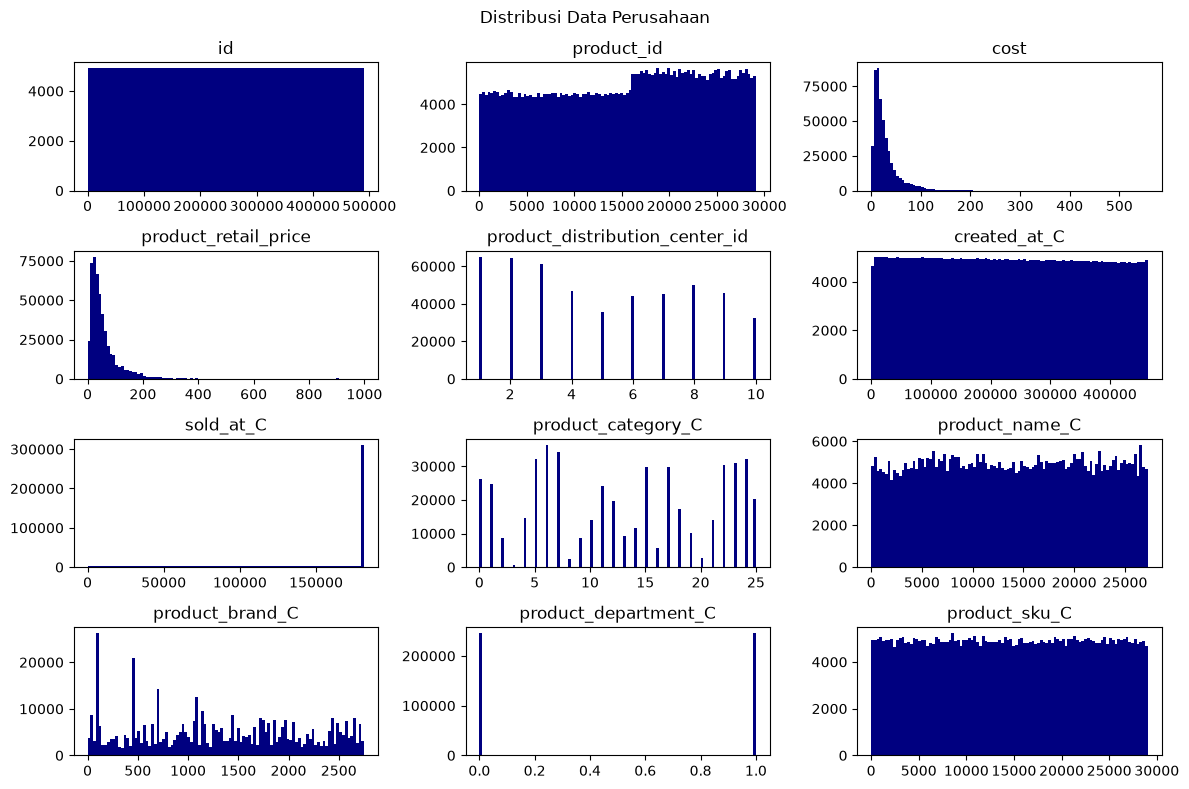

In [23]:
numerik = df_coder.select_dtypes(include=["float64", "int64"])

numerik.hist(color='navy', figsize=(12,8), bins=100, grid=False)
plt.suptitle("Distribusi Data Perusahaan")
plt.tight_layout()
plt.show()

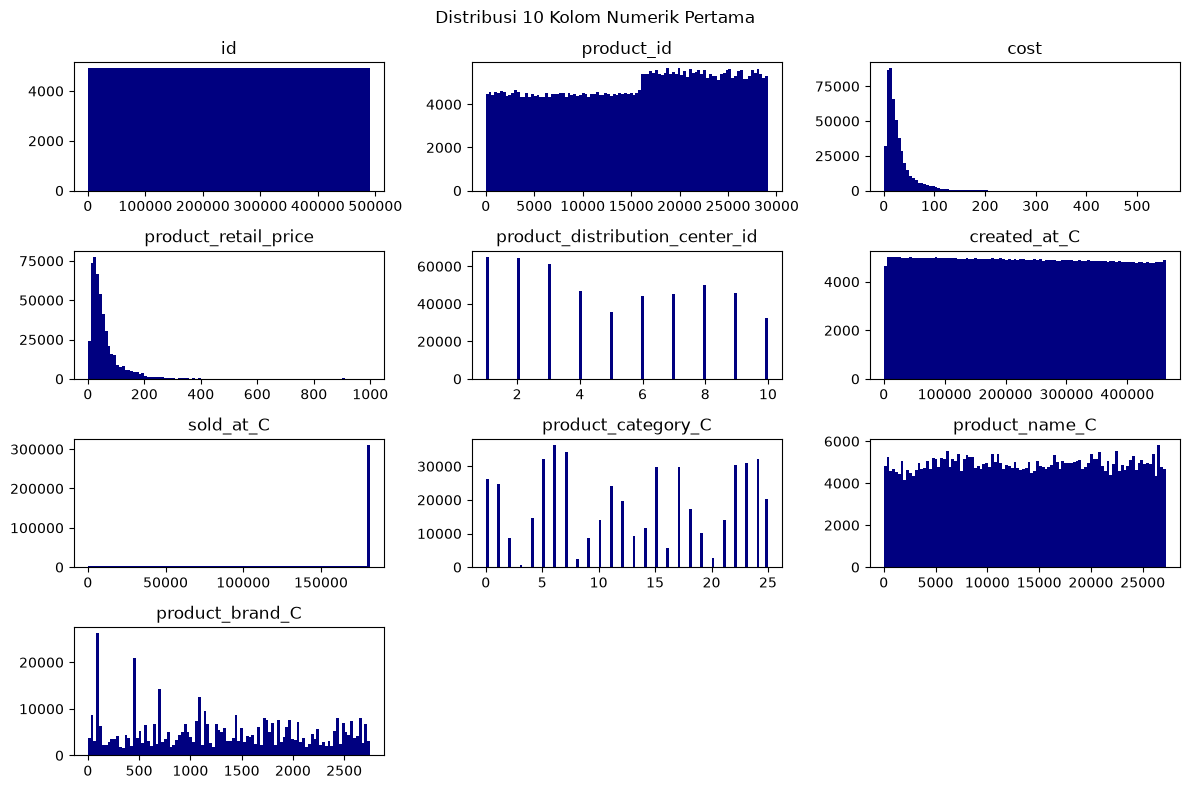

In [24]:
# Memilih hanya 10 kolom numerik pertama
numerik_top10 = df_coder.select_dtypes(include=["float64", "int64"]).iloc[:, :10]

# Membuat histogram khusus 10 kolom tersebut
numerik_top10.hist(color='navy', figsize=(12, 8), bins=100, grid=False)
plt.suptitle("Distribusi 10 Kolom Numerik Pertama")
plt.tight_layout()
plt.show()

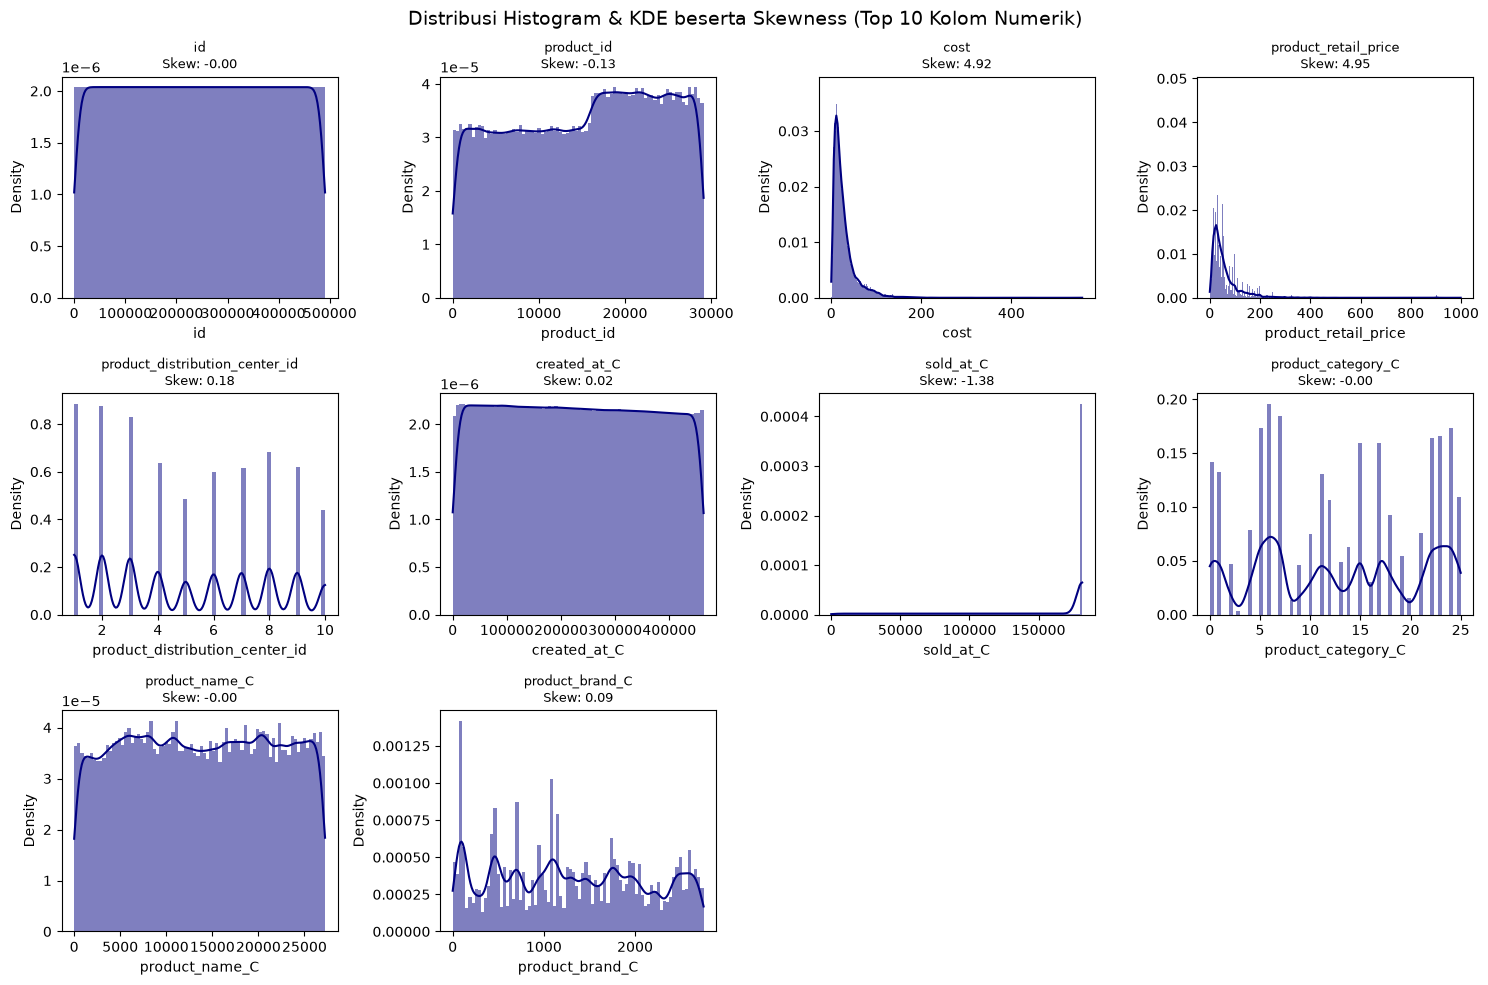

In [25]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Memilih 10 kolom numerik pertama dari DataFrame
numerik_top10 = df_coder.select_dtypes(include=["float64", "int64"]).iloc[:, :10]

# 2. Menghitung nilai skewness
skew_values = numerik_top10.skew()

# 3. Membuat subplot grid (3 baris x 4 kolom)
fig, axes = plt.subplots(nrows=3, ncols=4, figsize=(15, 10))
axes = axes.flatten()

for i, col in enumerate(numerik_top10.columns):
    # Membuat plot histogram sekaligus garis KDE
    sns.histplot(
        numerik_top10[col].dropna(), 
        color='navy', 
        kde=True, 
        ax=axes[i], 
        stat="density", 
        edgecolor='none'
    )
    
    # Menampilkan nama kolom dan nilai skewness di judul subplot
    sk = skew_values[col]
    axes[i].set_title(f"{col}\nSkew: {sk:.2f}", fontsize=9)
    axes[i].grid(False)

# Menghapus kotak subplot yang kosong (karena grid 12, data hanya 10)
for j in range(i + 1, len(axes)):
    fig.delaxes(axes[j])

plt.suptitle("Distribusi Histogram & KDE beserta Skewness (Top 10 Kolom Numerik)", fontsize=14, y=0.98)
plt.tight_layout()
plt.show()

### Insight


### Heatmap

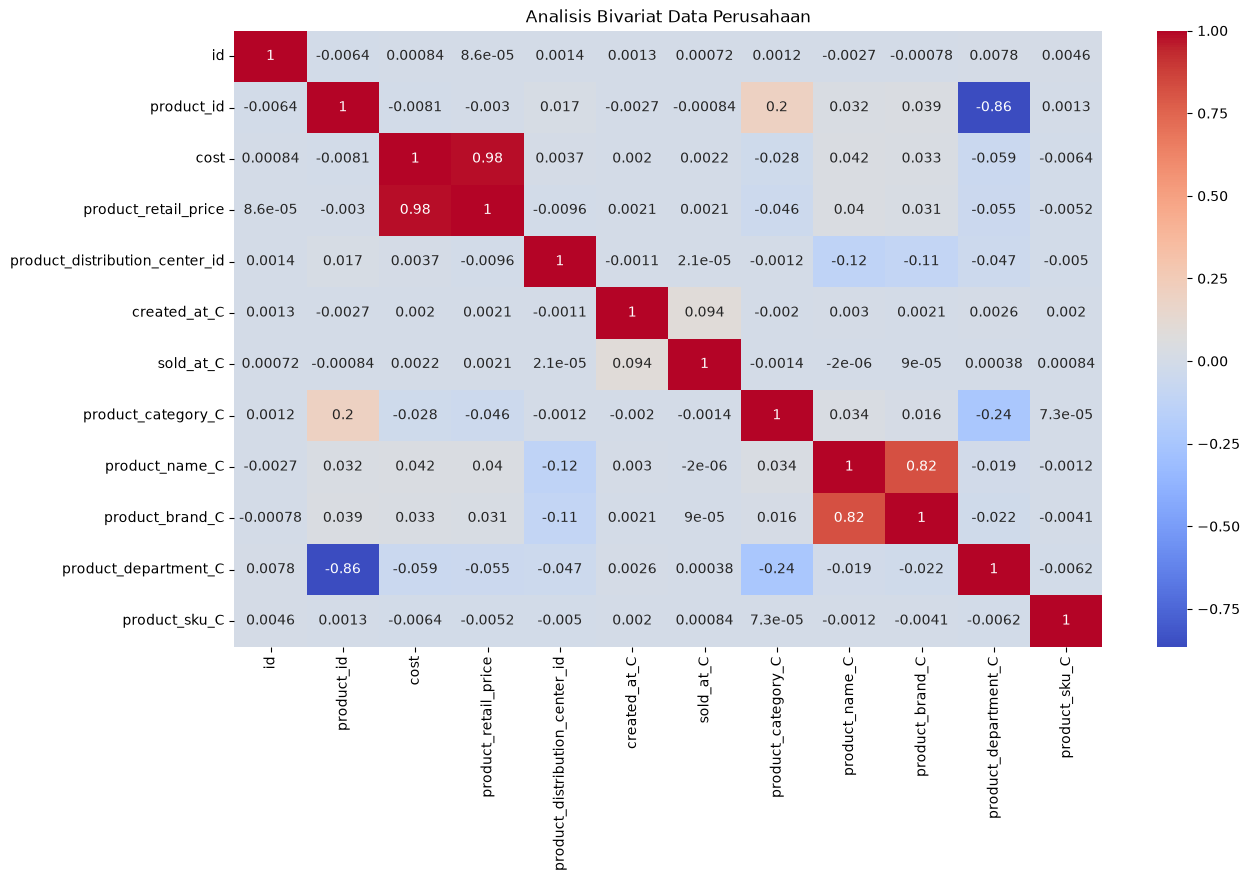

In [26]:
numerik = df_coder.select_dtypes(include=("float64", "int64"))

df_corr = numerik.corr()
plt.figure(figsize=(14, 8))
sns.heatmap(
    df_corr,
    annot=True,
    cmap="coolwarm"
)
plt.title("Analisis Bivariat Data Perusahaan")
plt.show()

In [27]:
numeric_df = df_coder.select_dtypes(include=["number"])

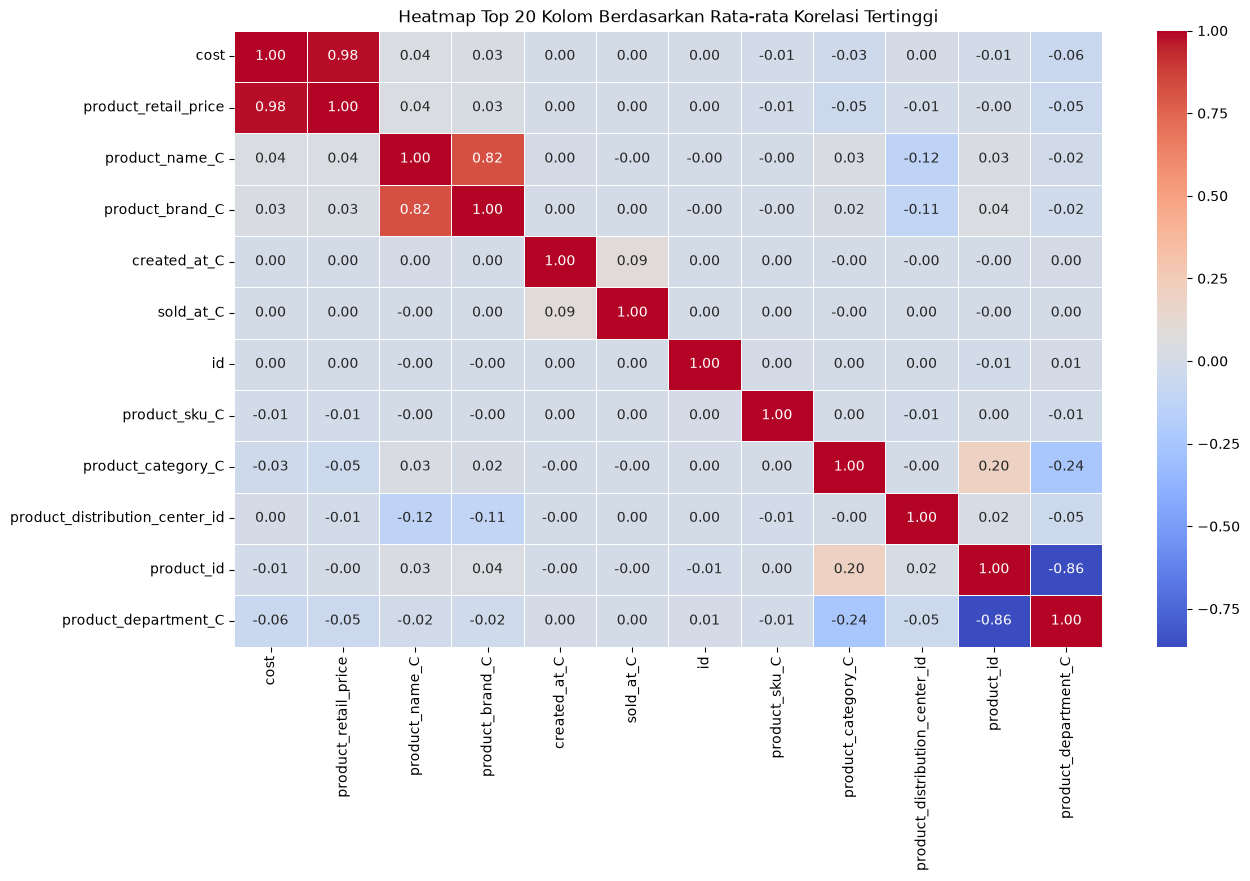

In [28]:
'''
Karena data kolomnya terlalu banyak, maka dari itu dibuat top 20
'''
# Hitung matriks korelasi absolut, lalu cari 20 kolom dengan rata-rata korelasi tertinggi
top_corr_cols = numeric_df.corr().mean().nlargest(20).index
corr_top = numeric_df[top_corr_cols].corr()

# Plot heatmap 10x10
plt.figure(figsize=(14, 8))
sns.heatmap(corr_top, annot=True, cmap="coolwarm", fmt=".2f", linewidths=0.5)
plt.title("Heatmap Top 20 Kolom Berdasarkan Rata-rata Korelasi Tertinggi")
plt.show()

### Insight


# Analisa
Setelah membuat heatmap berdasarkan rata-rata korelasi, ditemukan beberapa variabel yang menarik untuk dianalisis lebih lanjut terhadap sold_at, yaitu product_category, product_department, dan product_retail_price.
Variabel-variabel tersebut dipilih untuk mengetahui apakah terdapat hubungan antara jenis produk, jenis kelamin, dan harga produk dengan jumlah pembelian.

# Ekspor Data

In [29]:
df_copy.to_csv("inventory_items_bersih.csv")

In [30]:
df.to_csv("inventory_items1.csv")

In [31]:
df_copy.info()

<class 'pandas.DataFrame'>
RangeIndex: 490705 entries, 0 to 490704
Data columns (total 12 columns):
 #   Column                          Non-Null Count   Dtype              
---  ------                          --------------   -----              
 0   id                              490705 non-null  int64              
 1   product_id                      490705 non-null  int64              
 2   created_at                      490705 non-null  datetime64[us, UTC]
 3   sold_at                         181759 non-null  datetime64[us, UTC]
 4   cost                            490705 non-null  float64            
 5   product_category                490705 non-null  str                
 6   product_name                    490676 non-null  str                
 7   product_brand                   490304 non-null  str                
 8   product_retail_price            490705 non-null  float64            
 9   product_department              490705 non-null  str                
 10  product

In [32]:
df_copy['created_at'] = df_copy['created_at'].dt.tz_localize(None)
df_copy['sold_at'] = df_copy['sold_at'].dt.tz_localize(None)

# 2. Setelah itu, jalankan kembali perintah export ke Excel
df_copy.to_excel("inventory_items_bersih2.xlsx", index=False)

In [33]:
df_copy


,id,product_id,created_at,sold_at,cost,product_category,product_name,product_brand,product_retail_price,product_department,product_sku,product_distribution_center_id
0,67971,13844,2022-07-02 07:09:20,2022-07-24 06:33:20,2.76804,Accessories,(ONE) 1 Satin Headband,Funny Girl Designs,6.99,Women,2A3E953A5E3D81E67945BCE5519F84C8,7
1,67972,13844,2023-12-20 03:28:00,NaT,2.76804,Accessories,(ONE) 1 Satin Headband,Funny Girl Designs,6.99,Women,2A3E953A5E3D81E67945BCE5519F84C8,7
2,67973,13844,2023-06-04 02:53:00,NaT,2.76804,Accessories,(ONE) 1 Satin Headband,Funny Girl Designs,6.99,Women,2A3E953A5E3D81E67945BCE5519F84C8,7
3,72863,13844,2021-10-16 22:58:52,2021-11-22 02:19:52,2.76804,Accessories,(ONE) 1 Satin Headband,Funny Girl Designs,6.99,Women,2A3E953A5E3D81E67945BCE5519F84C8,7
4,72864,13844,2021-08-07 16:33:00,NaT,2.76804,Accessories,(ONE) 1 Satin Headband,Funny Girl Designs,6.99,Women,2A3E953A5E3D81E67945BCE5519F84C8,7
...,...,...,...,...,...,...,...,...,...,...,...,...
490700,311018,25590,2021-12-07 12:47:00,NaT,10.39200,Underwear,ck one Men's Micro Slim Fit Boxer,Calvin Klein,24.00,Men,F220707C3AFE39D1779E0A34AF72BB7F,3
490701,451084,25590,2023-10-10 11:57:57,2023-11-27 11:28:57,10.39200,Underwear,ck one Men's Micro Slim Fit Boxer,Calvin Klein,24.00,Men,F220707C3AFE39D1779E0A34AF72BB7F,3
490702,451085,25590,2020-11-20 05:55:00,NaT,10.39200,Underwear,ck one Men's Micro Slim Fit Boxer,Calvin Klein,24.00,Men,F220707C3AFE39D1779E0A34AF72BB7F,3
490703,486057,25590,2023-02-26 22:35:12,2023-04-23 01:24:12,10.39200,Underwear,ck one Men's Micro Slim Fit Boxer,Calvin Klein,24.00,Men,F220707C3AFE39D1779E0A34AF72BB7F,3
